# Speed Benchmark Comparison ESM3di vs ProstT5 vs ColabFold

This is temporary. ColabFold Results are missing and for meaningful results it would be good to run on an isolated gpu & cpu...

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import os 

# function that reads fasta file and returns length statistics of the sequences in it
def get_fasta_length_stats(fasta_file):
    from Bio import SeqIO
    lengths = [len(record.seq) for record in SeqIO.parse(fasta_file, "fasta")]
    length_stats = {
        "min_length": min(lengths),
        "max_length": max(lengths),
        "mean_length": sum(lengths) / len(lengths),
        "median_length": sorted(lengths)[len(lengths) // 2],
        "num_sequences": len(lengths)
    }
    return length_stats

fastas = [f for f in os.listdir("data/length_bins") if f.endswith(".fasta")]
sorted_fastas = sorted(fastas, key=lambda x: int(x.split("_")[1].split(".")[0][1:]))

for fasta_file in sorted_fastas:
    fasta_path = os.path.join("data/length_bins", fasta_file)
    stats = get_fasta_length_stats(fasta_path)
    print(f"Stats for {fasta_file}: {stats}")

Stats for bin_L100.fasta: {'min_length': 98, 'max_length': 102, 'mean_length': 100.4375, 'median_length': 101, 'num_sequences': 32}
Stats for bin_L200.fasta: {'min_length': 198, 'max_length': 202, 'mean_length': 200.0625, 'median_length': 201, 'num_sequences': 32}
Stats for bin_L300.fasta: {'min_length': 298, 'max_length': 302, 'mean_length': 299.875, 'median_length': 300, 'num_sequences': 32}
Stats for bin_L400.fasta: {'min_length': 398, 'max_length': 402, 'mean_length': 399.875, 'median_length': 400, 'num_sequences': 32}
Stats for bin_L500.fasta: {'min_length': 498, 'max_length': 502, 'mean_length': 499.375, 'median_length': 500, 'num_sequences': 32}
Stats for bin_L600.fasta: {'min_length': 598, 'max_length': 603, 'mean_length': 600.46875, 'median_length': 601, 'num_sequences': 32}
Stats for bin_L700.fasta: {'min_length': 695, 'max_length': 704, 'mean_length': 699.71875, 'median_length': 701, 'num_sequences': 32}
Stats for bin_L800.fasta: {'min_length': 795, 'max_length': 806, 'mean_

# Clean Plot(s) With Final Results

- **Runtime as a Function of Number of Sequences**
- **Runtime as a Function of Sequence Length**  
With a fix number of sequences per length bin (512), larger number of seqs means model init etc. becomes negligible for total runtime 


Shared style (fonts, sizes, method colours, export) comes from `../pub_style.py`. Figures are saved to `figures/` as vector PDF and 600 dpi PNG: one per panel and one combined.

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")  # benchmarks/ holds the shared figure style and plotting functions
from pub_style import (
    METHOD_COLOURS, MM, MUTED_TEXT, REFERENCE_LINEWIDTH, WIDTH_DOUBLE,
    add_panel_labels, save_pub, use_pub_style,
)
from fig_panels import (
    MARKER, MODEL_LABELS, MODEL_REPEATS, label_line, plot_runtime_vs_length,
    plot_runtime_vs_nseq, runtime_summary, use_log_axis,
)

use_pub_style()
FIG_DIR = Path("figures")

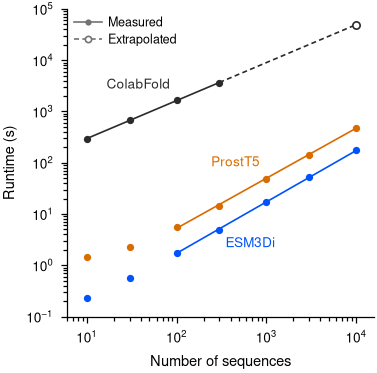

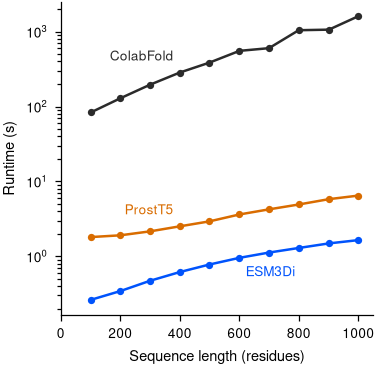

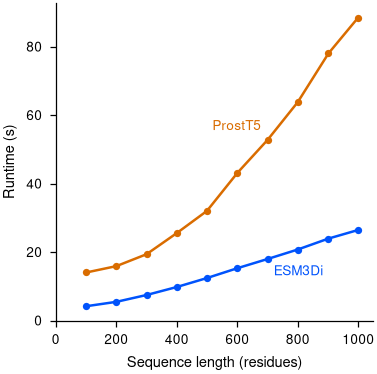

In [8]:
nseq_df = pd.read_csv("results/final_nseq.csv")
length_df = pd.read_csv("results/final_length_bins.csv")            # 32 sequences per bin for 
length_plm_df = pd.read_csv("results/final_length_bins_plms.csv")   # 512 sequences per bin


def draw_nseq(ax):
    plot_runtime_vs_nseq(ax, nseq_df)#, title="Runtime vs. number of sequences")


def draw_length_all(ax):
    curves = plot_runtime_vs_length(ax, length_df, ["esm3di", "prostt5", "colabfold"], log_y=True,)
                                    #title="Runtime vs. length (32 seq. per bin)")
    # Labels above-left of the line, ESM3Di below-right so it stays clear of ProstT5
    for model, bin_index, dx, dy, ha, va in (
        ("colabfold", 3, -3, 4, "right", "bottom"),
        ("prostt5", 3, -3, 4, "right", "bottom"),
        ("esm3di", 5, 3, -4, "left", "top"),
    ):
        point = curves[model].iloc[bin_index]
        label_line(ax, point["seq_length"], point["mean"], MODEL_LABELS[model], model,
                   dx=dx, dy=dy, ha=ha, va=va)


def draw_length_plm(ax):
    curves = plot_runtime_vs_length(ax, length_plm_df, ["esm3di", "prostt5"], log_y=False,)
                                    #title="Runtime vs. length (512 seq. per bin)")
    for model, dx, dy, ha, va in (("prostt5", -3, 3, "right", "bottom"), ("esm3di", 3, -3, "left", "top")):
        point = curves[model].iloc[6]
        label_line(ax, point["seq_length"], point["mean"], MODEL_LABELS[model], model,
                   dx=dx, dy=dy, ha=ha, va=va)


PANELS = {
    "speed_runtime_vs_nseq": draw_nseq,
    "speed_runtime_vs_length": draw_length_all,
    "speed_runtime_vs_length_plms": draw_length_plm,
}

# One figure per panel
for name, draw in PANELS.items():
    fig, ax = plt.subplots(figsize=(65 * MM, 65 * MM), layout="constrained")
    draw(ax)
    save_pub(fig, name, FIG_DIR)
    plt.show()

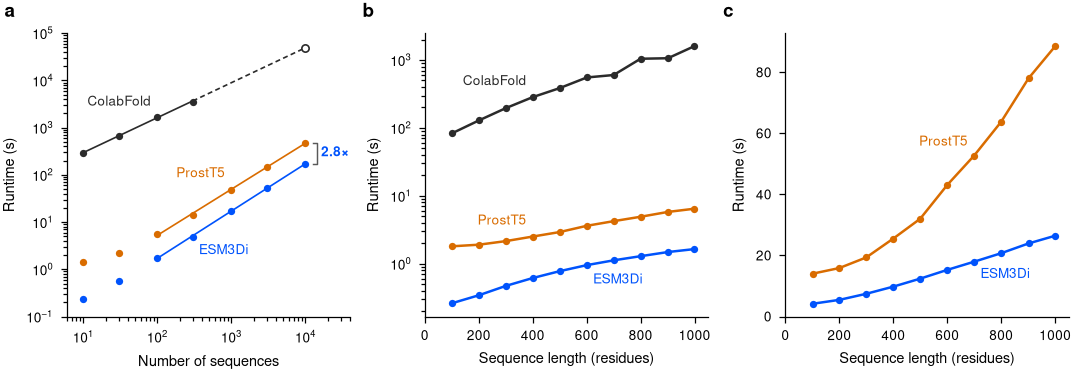

In [5]:
# Combined figure (full page width)
fig, axes = plt.subplots(1, 3, figsize=(WIDTH_DOUBLE, 64 * MM), layout="constrained")
for ax, draw in zip(axes, PANELS.values()):
    draw(ax)
add_panel_labels(axes)
save_pub(fig, "speed_combined", FIG_DIR)
plt.show()

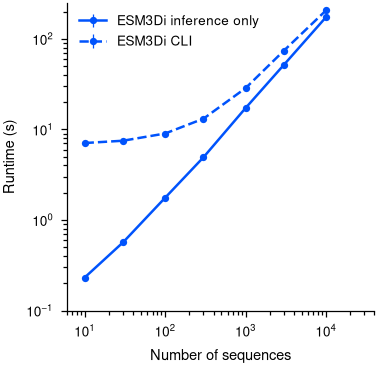

In [6]:
# plot only esm3di from nseq_df
# and esm3di from /results/final_nseq_esm3di_cli.csv
# to compare esm3di inference only vs CLI time, exlude the first of the 6 repetitions as in the cell above

cli_df = pd.read_csv("results/final_nseq_esm3di_cli.csv")
repetitions = [2, 3, 4, 5, 6]

def esm3di_summary(df):
    rows = df[(df["model_name"] == "esm3di") & (df["repetition"].isin(repetitions))]
    return (
        rows.groupby("num_sequences")["wall_time_seconds"]
        .agg(mean="mean", std="std")
        .sort_index()
    )

inference_summary = esm3di_summary(nseq_df)
cli_summary = esm3di_summary(cli_df)

fig, ax = plt.subplots(figsize=(65 * MM, 65 * MM), layout="constrained")
colour = METHOD_COLOURS["ESM3Di"]
for summary, label, linestyle in (
    (inference_summary, "ESM3Di inference only", "-"),
    (cli_summary, "ESM3Di CLI", "--"),
):
    ax.errorbar(
        summary.index,
        summary["mean"],
        yerr=summary["std"].fillna(0),
        color=colour,
        label=label,
        elinewidth=0.6,
        capsize=0,
        **{**MARKER, "ls": linestyle},
    )

ax.set_xscale("log")
ax.set_yscale("log")
use_log_axis(ax.xaxis)
use_log_axis(ax.yaxis)
ax.set_xlim(6, 4e4)
y_max = max(
    (summary["mean"] + summary["std"]).max()
    for summary in (inference_summary, cli_summary)
)
ax.set_ylim(0.1, y_max * 1.2)
ax.set_box_aspect(1)
ax.set_xlabel("Number of sequences")
ax.set_ylabel("Runtime (s)")
ax.legend(frameon=False)
save_pub(fig, "speed_runtime_vs_nseq_esm3di_cli", FIG_DIR)
plt.show()


## End-to-end speed comparison (recommended)

All methods are timed as the full CLI call (process start, model loading, inference, output), so the comparison is symmetric. 
ESM3Di and ProstT5 are fitted with $t(n) = t_0 + n\,c$ ($t_0$: fixed startup cost, $c$: time per sequence); 
ColabFold (run without MSA) with a power law, extrapolated to 10,000 sequences. Throughput labels are measured values at 10,000 sequences.

ESM3Di    startup  6.89 s    21.1 ms/seq
ProstT5   startup  0.92 s    47.0 ms/seq
ColabFold runtime ~ n^0.74; extrapolated to 10,000: 49,372 s
ESM3Di    measured throughput at n = 10,000: 48.5 seq/s
ProstT5   measured throughput at n = 10,000: 20.7 seq/s
ColabFold measured throughput at n = 300: 0.1 seq/s


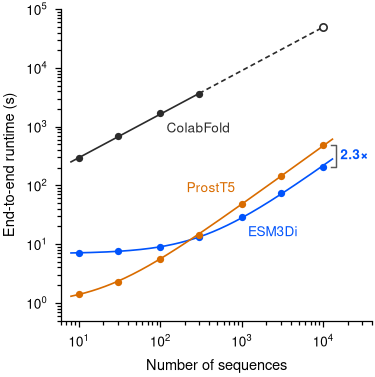

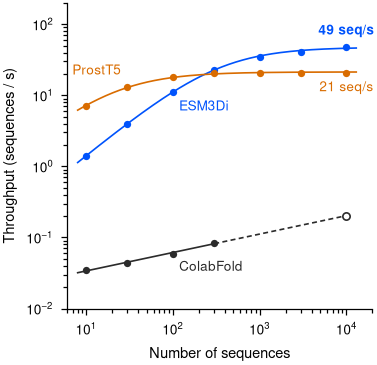

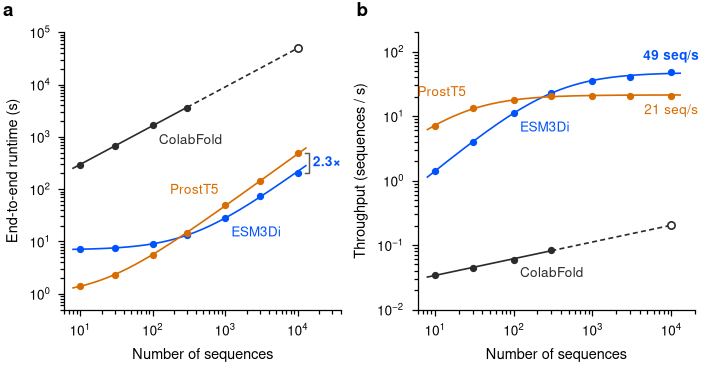

In [7]:
# End-to-end comparison: every method timed as the full CLI call (process start, model
# loading, inference, output).
#   ESM3Di, ProstT5: t(n) = t0 + n * c  (t0 = fixed startup cost, c = time per sequence)
#   ColabFold (no MSA): power law, a straight line on log-log axes, extrapolated to 10,000
from pub_style import WIDTH_ONEHALF

E2E_SOURCES = {
    # name: (csv, model_name, repetitions)
    "ESM3Di": ("results/final_nseq_esm3di_cli.csv", "esm3di", [2, 3, 4, 5, 6]),
    "ProstT5": ("results/final_nseq.csv", "prostt5", [2, 3, 4, 5, 6]),
    "ColabFold": ("results/final_nseq.csv", "colabfold", [1, 2]),
}
MAX_N = 10_000


def e2e_summary(csv, model_name, repetitions):
    df = pd.read_csv(csv)
    rows = df[(df["model_name"] == model_name) & (df["repetition"].isin(repetitions))]
    return rows.groupby("num_sequences")["wall_time_seconds"].agg(mean="mean", std="std").sort_index()


def fit_startup_and_rate(summary):
    """Fit t = t0 + n * c with relative residuals, so small and large n count equally."""
    n, t = summary.index.to_numpy(dtype=float), summary["mean"].to_numpy()
    c, t0 = np.polyfit(n, t, 1, w=1 / t)
    return lambda x: t0 + c * x, (t0, c)


def fit_power_law(summary):
    """Fit log10 t = a + b log10 n (a straight line on log-log axes)."""
    b, a = np.polyfit(np.log10(summary.index), np.log10(summary["mean"]), 1)
    return lambda x: 10 ** (a + b * np.log10(x)), b


e2e = {name: e2e_summary(*source) for name, source in E2E_SOURCES.items()}
e2e_fits = {}
for name in ("ESM3Di", "ProstT5"):
    e2e_fits[name], (t0, c) = fit_startup_and_rate(e2e[name])
    print(f"{name:9s} startup {t0:5.2f} s   {1000 * c:5.1f} ms/seq")
e2e_fits["ColabFold"], exponent = fit_power_law(e2e["ColabFold"])
print(f"ColabFold runtime ~ n^{exponent:.2f}; extrapolated to {MAX_N:,}: "
      f"{e2e_fits['ColabFold'](MAX_N):,.0f} s")
for name, summary in e2e.items():
    n_last = summary.index.max()
    print(f"{name:9s} measured throughput at n = {n_last:,}: {n_last / summary.loc[n_last, 'mean']:.1f} seq/s")

E2E_MARKER = dict(marker="o", ms=3.5, mew=0, ls="none", zorder=3)
OPEN_MARKER = dict(marker="o", ms=3.5, mfc="white", mew=0.8, ls="none", zorder=3)
EXTRAPOLATED = (0, (3, 2))


def text_label(ax, x, y, text, method, dx, dy, ha="left", va="bottom", **kwargs):
    ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                color=METHOD_COLOURS[method], fontsize=6.5, **kwargs)


def plot_fit(ax, name, transform=lambda n, t: t):
    """Fitted curve over the measured range; dashed extrapolation (open circle) up to MAX_N."""
    summary, fit, colour_ = e2e[name], e2e_fits[name], METHOD_COLOURS[name]
    n_min, n_max = summary.index.min(), summary.index.max()
    n_measured = np.geomspace(n_min * 0.8, n_max * 1.3 if n_max >= MAX_N else n_max, 200)
    ax.plot(n_measured, transform(n_measured, fit(n_measured)), color=colour_, lw=0.8, zorder=2)
    if n_max < MAX_N:
        n_ext = np.geomspace(n_max, MAX_N, 100)
        ax.plot(n_ext, transform(n_ext, fit(n_ext)), color=colour_, lw=0.8, ls=EXTRAPOLATED, zorder=2)
        ax.plot(MAX_N, transform(MAX_N, fit(MAX_N)), mec=colour_, **OPEN_MARKER)


def plot_e2e_runtime(ax):
    """End-to-end runtime vs number of sequences, with fits and the measured speed-up."""
    for name, summary in e2e.items():
        plot_fit(ax, name)
        ax.errorbar(summary.index, summary["mean"], yerr=summary["std"].fillna(0),
                    color=METHOD_COLOURS[name], elinewidth=0.6, capsize=0, **E2E_MARKER)

    # Measured end-to-end speed-up at the largest set
    y_esm, y_prost = e2e["ESM3Di"].loc[MAX_N, "mean"], e2e["ProstT5"].loc[MAX_N, "mean"]
    x_bracket = MAX_N * 1.45
    ax.plot([x_bracket / 1.15, x_bracket, x_bracket, x_bracket / 1.15], [y_esm, y_esm, y_prost, y_prost],
            color=MUTED_TEXT, lw=REFERENCE_LINEWIDTH)
    ax.text(x_bracket * 1.12, np.sqrt(y_esm * y_prost), f"{y_prost / y_esm:.1f}×",
            ha="left", va="center", fontsize=6.5, fontweight="bold", color=METHOD_COLOURS["ESM3Di"])

    ax.set_xscale("log")
    ax.set_yscale("log")
    use_log_axis(ax.xaxis)
    use_log_axis(ax.yaxis)
    ax.set_xlim(6, 4e4)
    ax.set_ylim(0.5, 1e5)
    ax.set_box_aspect(1)
    ax.set_xlabel("Number of sequences")
    ax.set_ylabel("End-to-end runtime (s)")

    text_label(ax, 100, e2e_fits["ColabFold"](100), "ColabFold", "ColabFold", dx=3, dy=-4, va="top")
    text_label(ax, 1000, e2e_fits["ProstT5"](1000), "ProstT5", "ProstT5", dx=-3, dy=4, ha="right")
    text_label(ax, 1000, e2e_fits["ESM3Di"](1000), "ESM3Di", "ESM3Di", dx=3, dy=-4, va="top")


def plot_e2e_throughput(ax):
    """Sequences per second vs number of sequences; measured throughput at 10,000 labelled."""
    per_second = lambda n, t: n / t
    for name, summary in e2e.items():
        plot_fit(ax, name, transform=per_second)
        ax.plot(summary.index, summary.index / summary["mean"], color=METHOD_COLOURS[name], **E2E_MARKER)

    ax.set_xscale("log")
    ax.set_yscale("log")
    use_log_axis(ax.xaxis)
    use_log_axis(ax.yaxis)
    ax.set_xlim(6, 2e4)
    ax.set_ylim(0.01, 200)
    ax.set_box_aspect(1)
    ax.set_xlabel("Number of sequences")
    ax.set_ylabel("Throughput (sequences / s)")

    # Method names on the rising part, measured throughput at the largest set
    text_label(ax, 30, 30 / e2e["ProstT5"].loc[30, "mean"], "ProstT5", "ProstT5", dx=-3, dy=4, ha="right")
    text_label(ax, 100, 100 / e2e["ESM3Di"].loc[100, "mean"], "ESM3Di", "ESM3Di", dx=3, dy=-4, va="top")
    text_label(ax, 100, 100 / e2e_fits["ColabFold"](100), "ColabFold", "ColabFold", dx=3, dy=-4, va="top")
    for name, dy, va in (("ESM3Di", 4, "bottom"), ("ProstT5", -4, "top")):
        throughput = MAX_N / e2e[name].loc[MAX_N, "mean"]
        text_label(ax, MAX_N, throughput, f"{throughput:.0f} seq/s", name, dx=0, dy=dy, ha="center", va=va,
                   fontweight="bold" if name == "ESM3Di" else "normal")


E2E_PANELS = {
    "speed_e2e_runtime_vs_nseq": plot_e2e_runtime,
    "speed_e2e_throughput_vs_nseq": plot_e2e_throughput,
}
for name, draw in E2E_PANELS.items():
    fig, ax = plt.subplots(figsize=(65 * MM, 65 * MM), layout="constrained")
    draw(ax)
    save_pub(fig, name, FIG_DIR)
    plt.show()

fig, axes = plt.subplots(1, 2, figsize=(WIDTH_ONEHALF, 64 * MM), layout="constrained")
for ax, draw in zip(axes, E2E_PANELS.values()):
    draw(ax)
add_panel_labels(axes)
save_pub(fig, "speed_e2e_combined", FIG_DIR)
plt.show()